<a href="https://colab.research.google.com/github/vidub04/snm_project/blob/main/snm_MORAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!git clone https://github.com/Floris93100/reproducing-MORAL


Cloning into 'reproducing-MORAL'...
remote: Enumerating objects: 7068, done.
remote: Counting objects: 100% (36/36), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 7068 (delta 18), reused 14 (delta 5), pack-reused 7032 (from 1)
Receiving objects: 100% (7068/7068), 219.82 MiB | 20.66 MiB/s, done.
Resolving deltas: 100% (6012/6012), done.
Updating files: 100% (7017/7017), done.


In [ ]:
%cd /content/reproducing-MORAL

/content/reproducing-MORAL


In [ ]:
%cd reproducing-MORAL

/content/reproducing-MORAL


In [14]:
!rm -rf /content/reproducing-MORAL/data/output

In [ ]:
##INSTALLING REQUIREMENTS

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [8]:
!pip install numpy

In [9]:
pip install scipy

In [10]:
pip install pandas

In [15]:
pip install torch

In [16]:
pip install torchvision

In [17]:
pip install torch-geometric networkx tqdm requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 23.7 MB/s  0:00:00


In [18]:
pip install gdown matplotlib plotly

In [19]:
!pip install loguru powerlaw cpnet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [cpnet]


In [20]:
!pip install simanneal codecarbon

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.0/8.0 MB 44.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 53.3 MB/s  0:00:00
  Attempting uninstall: psutil
    Found existing installation: psutil 5.9.5
    Uninstalling psutil-5.9.5:
      Successfully uninstalled psutil-5.9.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [codecarbon]


In [21]:
pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 7.6 MB/s  0:00:03


In [24]:
%cd /content/reproducing-MORAL/scripts

/content/reproducing-MORAL/scripts


In [ ]:
##FACEBOOK MODEL TRAINING

In [25]:
!python main.py   --dataset facebook   --model gae   --fair_model moral   --device cpu   --epochs 500

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
2026-11-16 16:54:53.219 +00:00 | INFO     | __main__:main:334 - Processing dataset 'facebook' with model 'gae'.
2026-11-16 16:54:53.232 +00:00 | INFO     | __main__:run_single:145 - Run 1/3 — seed=0
[codecarbon WARNING @ 16:54:53] Multiple instances of codecarbon are allowed to run at the same time.
/content/reproducing-MORAL/scripts/helpers/datasets.py:504: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, val

In [26]:
import torch

path = "/content/reproducing-MORAL/data/output/three_classifiers_facebook_MORAL_GAE_0.pt"

result = torch.load(
    path,
    map_location="cpu",
    weights_only=False
)

for i, item in enumerate(result):
    print(f"Element {i}:")
    print("Shape:", item.shape if hasattr(item, "shape") else None)
    print("Type:", type(item))
    print("First 10 values:", item[:10] if hasattr(item, "__getitem__") else item)

Element 0:
Shape: torch.Size([10704])
Type: <class 'torch.Tensor'>
First 10 values: tensor([ 3.7176,  4.4484, 17.9260,  3.5568,  2.9460,  1.1651,  2.4718,  3.2893,
         6.8522,  4.1086])
Element 1:
Shape: torch.Size([10704])
Type: <class 'torch.Tensor'>
First 10 values: tensor([2, 0, 0, 0, 1, 0, 0, 0, 0, 1])


In [ ]:
##RESULTS

In [28]:
from helpers.metrics import get_results, print_results
from helpers.metrics import get_results_curves
from helpers.plots import plot_metric_curves_grid
from pathlib import Path
from helpers.utils import get_dataset, print_graph_statistics
from helpers.metrics import calculate_edge_homophily

datasets = ["facebook"]
split_path = "../data/splits"
output_folder = "../data/output"
csv_out = f"{output_folder}/MORAL_edge_distributions_fb.csv"

datasets_results= ["facebook"]
output_folder = "../data/output"
k = 1000

results = get_results(
    datasets=datasets_results,
    folder=output_folder,
    graph_stats_csv=csv_out,
    splits_dir=split_path,
    k=k,
)
print_results(results, k)

/content/reproducing-MORAL/scripts/helpers/datasets.py:504: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, values, shape)


Dataset  | Raw NDKL@1000   | Reranked NDKL@1000 | Raw AWRF@1000   | Reranked AWRF@1000 | Raw DP          | Reranked DP     | Precision@1000  | NDCG@1000      
--------------------------------------------------------------------------------------------------------------------------------------------------------------
facebook | 0.0213 ± 0.0080 | 0.0084 ± 0.0000    | 0.0279 ± 0.0049 | 0.0032 ± 0.0000    | 0.0143 ± 0.0024 | 0.0006 ± 0.0007 | 0.9823 ± 0.0025 | 0.9970 ± 0.0018


In [ ]:
##NBA MODEL TRAINING

In [ ]:
!python main.py   --dataset nba   --model gae   --fair_model moral   --device cpu   --epochs 500

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
2026-11-16 18:47:38.502 +00:00 | INFO     | __main__:main:334 - Processing dataset 'nba' with model 'gae'.
2026-11-16 18:47:38.507 +00:00 | INFO     | __main__:run_single:145 - Run 1/3 — seed=0
[codecarbon WARNING @ 18:47:38] Multiple instances of codecarbon are allowed to run at the same time.
/content/reproducing-MORAL/scripts/helpers/datasets.py:504: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, values, 

In [ ]:
##RESULTS

In [35]:
datasets = ["nba"]
split_path = "../data/splits"
output_folder = "../data/output"
csv_out = f"{output_folder}/MORAL_edge_distributions_nba.csv"
datasets_results= ["nba"]
output_folder = "../data/output"
k = 1000

results = get_results(
    datasets=datasets_results,
    folder=output_folder,
    graph_stats_csv=csv_out,
    splits_dir=split_path,
    k=k,
)
print_results(results, k)

Dataset | Raw NDKL@1000   | Reranked NDKL@1000 | Raw AWRF@1000   | Reranked AWRF@1000 | Raw DP          | Reranked DP     | Precision@1000  | NDCG@1000      
-------------------------------------------------------------------------------------------------------------------------------------------------------------
nba     | 0.0218 ± 0.0012 | 0.0059 ± 0.0000    | 0.0280 ± 0.0079 | 0.0020 ± 0.0000    | 0.0077 ± 0.0040 | 0.0154 ± 0.0062 | 0.7627 ± 0.0104 | 0.9618 ± 0.0025


In [ ]:
##GERMAN MODELTRAINING

In [36]:
!python main.py   --dataset german   --model gae   --fair_model moral   --device cpu   --epochs 500

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
2026-11-16 19:17:01.407 +00:00 | INFO     | __main__:main:334 - Processing dataset 'german' with model 'gae'.
2026-11-16 19:17:01.412 +00:00 | INFO     | __main__:run_single:145 - Run 1/3 — seed=0
[codecarbon WARNING @ 19:17:01] Multiple instances of codecarbon are allowed to run at the same time.
/content/reproducing-MORAL/scripts/helpers/datasets.py:504: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  return torch.sparse_coo_tensor(indices, value

In [ ]:
##RESULTS

In [37]:
datasets = ["german"]
split_path = "../data/splits"
output_folder = "../data/output"
csv_out = f"{output_folder}/MORAL_edge_distributions_german.csv"
datasets_results= ["german"]
output_folder = "../data/output"
k = 1000

results = get_results(
    datasets=datasets_results,
    folder=output_folder,
    graph_stats_csv=csv_out,
    splits_dir=split_path,
    k=k,
)
print_results(results, k)

Dataset | Raw NDKL@1000   | Reranked NDKL@1000 | Raw AWRF@1000   | Reranked AWRF@1000 | Raw DP          | Reranked DP     | Precision@1000  | NDCG@1000      
-------------------------------------------------------------------------------------------------------------------------------------------------------------
german  | 0.0210 ± 0.0042 | 0.0068 ± 0.0000    | 0.0371 ± 0.0188 | 0.0021 ± 0.0000    | 0.0968 ± 0.0089 | 0.0109 ± 0.0025 | 0.9617 ± 0.0069 | 0.9947 ± 0.0022


In [38]:
import pandas as pd

for file in [
    "/content/reproducing-MORAL/data/output/MORAL_edge_distributions_fb.csv",
    "/content/reproducing-MORAL/data/output/MORAL_edge_distributions_german.csv",
    "/content/reproducing-MORAL/data/output/MORAL_edge_distributions_nba.csv"
]:
    df = pd.read_csv(file)
    print("\nFILE:", file)
    print("COLUMNS:", df.columns.tolist())
    print(df.head(5).to_string(index=False))


FILE: /content/reproducing-MORAL/data/output/MORAL_edge_distributions_fb.csv
COLUMNS: ['dataset', 'path', 'nodes', 'average_degree', 'global_E', 'global_00', 'global_01', 'global_11', 'global_p00', 'global_p01', 'global_p11', 'train_pos_shape', 'train_neg_shape', 'train_pos_neg_overlap', 'train_pos_E', 'train_pos_00', 'train_pos_01', 'train_pos_11', 'train_pos_p00', 'train_pos_p01', 'train_pos_p11', 'train_neg_E', 'train_neg_00', 'train_neg_01', 'train_neg_11', 'train_neg_p00', 'train_neg_p01', 'train_neg_p11', 'valid_pos_shape', 'valid_neg_shape', 'valid_pos_neg_overlap', 'valid_pos_E', 'valid_pos_00', 'valid_pos_01', 'valid_pos_11', 'valid_pos_p00', 'valid_pos_p01', 'valid_pos_p11', 'valid_neg_E', 'valid_neg_00', 'valid_neg_01', 'valid_neg_11', 'valid_neg_p00', 'valid_neg_p01', 'valid_neg_p11', 'test_pos_shape', 'test_neg_shape', 'test_pos_neg_overlap', 'test_pos_E', 'test_pos_00', 'test_pos_01', 'test_pos_11', 'test_pos_p00', 'test_pos_p01', 'test_pos_p11', 'test_neg_E', 'test_neg_

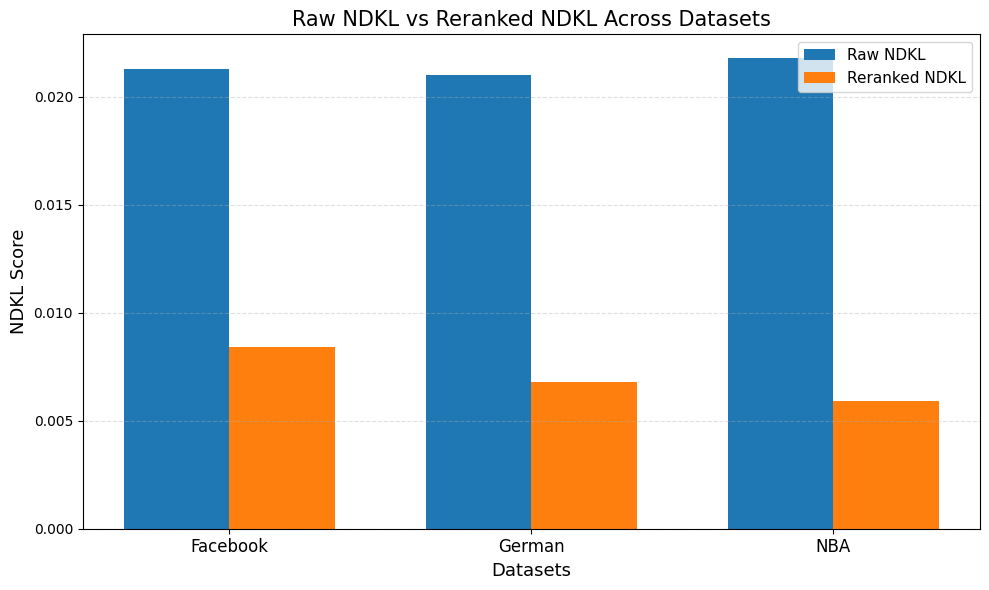

In [39]:
import matplotlib.pyplot as plt
import numpy as np

# Replace these example values with your actual NDKL results
datasets = ['Facebook', 'German', 'NBA']

raw_ndkl = [0.0213, 0.0210, 0.0218]
reranked_ndkl = [0.0084, 0.0068,0.0059 ]

# Bar positions
x = np.arange(len(datasets))
width = 0.35

# Create figure
plt.figure(figsize=(10, 6))

plt.bar(x - width/2, raw_ndkl, width,
        label='Raw NDKL')

plt.bar(x + width/2, reranked_ndkl, width,
        label='Reranked NDKL')

# Labels and formatting
plt.xlabel('Datasets', fontsize=13)
plt.ylabel('NDKL Score', fontsize=13)
plt.title('Raw NDKL vs Reranked NDKL Across Datasets',
          fontsize=15)

plt.xticks(x, datasets, fontsize=12)
plt.legend(fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()

# Save graph
plt.savefig('Raw_vs_Reranked_NDKL.png',
            dpi=300, bbox_inches='tight')

plt.show()